# 🚙 FlotaVisión: detector de camionetas **SUV** con visión computacional

| | |
|---|---|
| **Carrera** | Ingeniería de Software con Inteligencia Artificial — Semestre IV |
| **Módulo formativo** | Machine Learning y Deep Learning |
| **Semana 12** | Tarea: *Describe los principios de visión computacional y Machine Learning* |
| **Herramientas** | Anaconda · Jupyter Notebook · Python · OpenCV · NumPy · Matplotlib · Pandas · scikit-learn |

> **Caso propio basado en el ejemplo guiado *AgroVisión*.** Se reutiliza el mismo *pipeline* (adquisición → preprocesamiento → segmentación → detección → reconocimiento → decisión), pero aplicado a otro problema: **identificar, dentro de una flota de vehículos, cuáles son SUV**.

### Diferencias con el caso guiado (limones)

| AgroVisión (guiado) | FlotaVisión (este caso) |
|---|---|
| Limones (objetos redondos) | Vehículos vistos desde arriba (objetos **rectangulares**) |
| Caja recta `boundingRect` | Caja **rotada** `minAreaRect` (mide largo y ancho aunque el auto esté girado) |
| Diámetro en **mm** | Largo, ancho y área en **metros** |
| Clasifica por color / calibre / manchas | Clasifica por **dimensiones**: COMPACTO · SEDÁN · **SUV** · PICKUP; el color solo se reporta |
| Ángulo de cámara dado por el técnico | Ángulo de cámara **calculado automáticamente** con el patrón |
| Imágenes externas | Imágenes y datos **generados dentro del notebook** (no requiere archivos extra) |
| ML: k-NN | ML: k-NN **y** Árbol de decisión (que muestra las reglas que aprendió) |
| Anexo: webcam | Anexo: **validación** del sistema con 20 estacionamientos simulados |

> **Cómo trabajar:** ejecuta las celdas **en orden** con `Shift + Enter` (o *Kernel → Restart & Run All*). Donde veas **🧪 Pruébalo tú**, cambia valores y vuelve a ejecutar. Donde veas **❓ Pregunta**, responde en la celda de texto siguiente.

## 📖 El caso: «TransAndes Logística» necesita saber cuántas SUV tiene

*TransAndes Logística S.A.C.* (empresa ficticia) alquila vehículos a empresas mineras de **Arequipa**. Su patio tiene una **cámara cenital** (vista desde arriba) que vigila las plazas de estacionamiento.

Una minera ofrece un contrato, pero exige **camionetas SUV** (más anchas y altas, aptas para trocha). Hoy un supervisor recorre el patio con una libreta y se equivoca a menudo: confunde sedanes grandes con SUV.

> *«Usen la cámara del patio. Quiero que el sistema **detecte** cada vehículo, **mida** su largo y ancho en metros, diga **qué tipo es** y, sobre todo, **cuáles son SUV**. Al final díganme si nos alcanza para el contrato.»*

### Norma de clasificación (dimensiones vistas desde arriba)

| Tipo | Regla (en este orden) | Medidas típicas |
|---|---|---|
| 🟤 **PICKUP** | largo **≥ 5.05 m** (tiene caja de carga) | 5.2–5.5 m × 1.86–1.96 m |
| 🟢 **SUV** | ancho **≥ 1.83 m** | 4.4–4.85 m × 1.88–2.00 m |
| 🔵 **COMPACTO** | largo **< 4.25 m** | 3.6–4.1 m × 1.60–1.72 m |
| ⚪ **SEDÁN** | el resto | 4.4–4.8 m × 1.70–1.78 m |

**Contrato minero:** se necesitan **al menos 5 SUV y 2 PICKUP** visibles en el patio.

En el piso hay un **patrón de calibración**: un cuadrado blanco de **1 m × 1 m**. Con él convertiremos píxeles a metros.

**Material de trabajo** (se genera en el Paso 0, carpeta `imagenes/`):
- `patio_turno_dia.png` → foto del turno día.
- `patio_turno_noche.png` → foto del turno noche: un camión **golpeó el poste de la cámara** (quedó girada) y **hay poca luz**. Será el reto final.

---
## Paso 0 · Preparar el entorno en **Anaconda**

1. Abre **Anaconda Prompt** (menú Inicio) e instala OpenCV (el resto ya viene con Anaconda):
```bash
pip install opencv-python
```
2. Abre **Anaconda Navigator → Jupyter Notebook** (o escribe `jupyter notebook` en Anaconda Prompt), ve a la carpeta del proyecto y abre este archivo.

La siguiente celda importa las librerías y crea las carpetas de trabajo.

In [1]:
# === Librerías del proyecto ===
import os                              # rutas y carpetas
import cv2                             # OpenCV: visión computacional
import numpy as np                     # NumPy: matrices y vectores
import matplotlib.pyplot as plt        # Matplotlib: mostrar imágenes y gráficos
import pandas as pd                    # Pandas: tablas de resultados

print("OpenCV :", cv2.__version__)
print("NumPy  :", np.__version__)
print("Pandas :", pd.__version__)

for carpeta in ["imagenes", "datos", "resultados"]:
    os.makedirs(carpeta, exist_ok=True)
print("Carpetas listas:", os.listdir("."))

OpenCV : 5.0.0
NumPy  : 2.4.6
Pandas : 3.0.3
Carpetas listas: ['datos', 'FlotaVision_SUV.ipynb', 'imagenes', 'resultados']


In [2]:
# === Funciones de apoyo para mostrar imágenes ===
plt.rcParams["figure.dpi"] = 100

def mostrar(img, titulo="", tamano=(12, 8.5), cmap=None):
    """Muestra UNA imagen. OpenCV guarda en BGR y Matplotlib espera RGB: por eso convertimos."""
    plt.figure(figsize=tamano)
    if img.ndim == 3:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    else:
        plt.imshow(img, cmap=cmap or "gray")
    plt.title(titulo)
    plt.axis("off")
    plt.show()

def mostrar_varias(imagenes, titulos, columnas=3, tamano=(15, 4.5), cmap="gray"):
    """Muestra VARIAS imágenes en una cuadrícula."""
    filas = (len(imagenes) + columnas - 1) // columnas
    plt.figure(figsize=(tamano[0], tamano[1] * filas))
    for i, (img, tit) in enumerate(zip(imagenes, titulos)):
        plt.subplot(filas, columnas, i + 1)
        if img.ndim == 3:
            plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        else:
            plt.imshow(img, cmap=cmap)
        plt.title(tit)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

print("Funciones listas ✔")

Funciones listas ✔


### Generar el material del caso (simulador del patio)

Como no tenemos una cámara real sobre un estacionamiento, **simulamos** la vista cenital: el asfalto es gris, las líneas son blancas y cada vehículo se dibuja con sus **medidas reales** (carrocería, parabrisas, techo, faros y, en las pickup, la caja de carga).

> El simulador conoce la escala real (`ESCALA_GEN = 50 px/m`), pero **el sistema de visión NO la usa**: debe descubrirla midiendo el patrón de 1 m. El simulador también guarda la *verdad* (qué tipo es cada vehículo) para poder evaluar al sistema al final.

In [3]:
ESCALA_GEN = 50                       # px por metro: SOLO el simulador la conoce
ASFALTO = (72, 72, 72)                # gris (BGR)
FUENTE = cv2.FONT_HERSHEY_SIMPLEX

# Catálogo de medidas reales (metros) de cada tipo de vehículo
CATALOGO = {
    "COMPACTO": {"largo": (3.60, 4.10), "ancho": (1.60, 1.72)},
    "SEDAN":    {"largo": (4.40, 4.80), "ancho": (1.70, 1.78)},
    "SUV":      {"largo": (4.40, 4.85), "ancho": (1.88, 2.00)},
    "PICKUP":   {"largo": (5.20, 5.50), "ancho": (1.86, 1.96)},
}
# Colores de pintura (BGR)
PINTURAS = {"rojo": (40, 40, 200), "naranja": (30, 130, 240), "amarillo": (40, 200, 230),
            "verde": (60, 160, 40), "celeste": (220, 170, 60), "azul": (190, 90, 30),
            "morado": (150, 50, 120)}

def _rect_redondeado(img, x1, y1, x2, y2, r, color):
    x1, y1, x2, y2, r = map(int, (x1, y1, x2, y2, r))
    cv2.rectangle(img, (x1 + r, y1), (x2 - r, y2), color, -1)
    cv2.rectangle(img, (x1, y1 + r), (x2, y2 - r), color, -1)
    for cx, cy in [(x1 + r, y1 + r), (x2 - r, y1 + r), (x1 + r, y2 - r), (x2 - r, y2 - r)]:
        cv2.circle(img, (cx, cy), r, color, -1)

def dibujar_vehiculo(img, cx, cy, tipo, largo_m, ancho_m, pintura, hacia_arriba=True):
    L, W = largo_m * ESCALA_GEN, ancho_m * ESCALA_GEN
    x1, x2, top, bottom = cx - W / 2, cx + W / 2, cy - L / 2, cy + L / 2
    base = np.array(PINTURAS[pintura], float)
    color = tuple(int(v) for v in base)
    techo = tuple(int(v) for v in base * 0.85 + 38)      # techo un poco más claro
    caja = tuple(int(v) for v in base * 0.55)            # caja de carga más oscura
    vidrio = (48, 42, 38)

    def franja(d1, d2, col, margen=0.12):
        """Dibuja una franja entre d1 y d2 (fracción del largo medida desde el frente)."""
        if hacia_arriba:
            ya, yb = top + d1 * L, top + d2 * L
        else:
            ya, yb = bottom - d2 * L, bottom - d1 * L
        _rect_redondeado(img, x1 + margen * W, ya, x2 - margen * W, yb, min(6, W * 0.05), col)

    _rect_redondeado(img, x1, top, x2, bottom, W * 0.2, color)          # carrocería
    if tipo == "PICKUP":
        franja(0.20, 0.30, vidrio); franja(0.30, 0.46, techo); franja(0.46, 0.50, vidrio)
        franja(0.55, 0.95, caja, 0.10)
    elif tipo == "SUV":
        franja(0.20, 0.32, vidrio); franja(0.32, 0.86, techo); franja(0.86, 0.93, vidrio)
    else:
        franja(0.24, 0.36, vidrio); franja(0.36, 0.68, techo); franja(0.68, 0.78, vidrio)
    yf = top + 0.03 * L if hacia_arriba else bottom - 0.03 * L               # faros
    for xf in (x1 + 0.22 * W, x2 - 0.22 * W):
        cv2.ellipse(img, (int(xf), int(yf)), (int(0.12 * W), 4), 0, 0, 360, (215, 235, 240), -1)

X0, ANCHO_PLAZA, FILAS = 180, 135, [(150, 450), (550, 850)]   # 2 filas x 8 plazas

def generar_patio(vehiculos, semilla=0):
    """Dibuja el patio con los vehículos indicados. Devuelve (imagen, tabla con la verdad)."""
    rng = np.random.default_rng(semilla)
    img = np.full((1000, 1400, 3), ASFALTO, np.uint8)
    for ya, yb in FILAS:                                            # líneas de las plazas
        for k in range(9):
            x = X0 + k * ANCHO_PLAZA
            cv2.line(img, (x, ya), (x, yb), (235, 235, 235), 4)
    cv2.rectangle(img, (60, 475), (60 + ESCALA_GEN - 1, 475 + ESCALA_GEN - 1), (255, 255, 255), -1)
    cv2.putText(img, "1 m", (62, 462), FUENTE, 0.6, (230, 230, 230), 2)
    cv2.putText(img, "TRANSANDES - CAM 01", (520, 512), FUENTE, 0.9, (220, 220, 220), 2)

    verdad = []
    for v in vehiculos:
        fila, col = v["plaza"]
        tipo = str(v["tipo"])
        largo = rng.uniform(*CATALOGO[tipo]["largo"])
        ancho = rng.uniform(*CATALOGO[tipo]["ancho"])
        ya, yb = FILAS[fila]
        cx = X0 + col * ANCHO_PLAZA + ANCHO_PLAZA / 2 + rng.uniform(-6, 6)
        cy = (ya + yb) / 2 + rng.uniform(-10, 10)
        dibujar_vehiculo(img, cx, cy, tipo, largo, ancho, str(v["pintura"]), hacia_arriba=(fila == 0))
        verdad.append({"cx": cx, "cy": cy, "tipo_real": tipo, "pintura": str(v["pintura"]),
                       "largo_real": round(largo, 2), "ancho_real": round(ancho, 2)})

    ruido = rng.normal(0, 4, (*img.shape[:2], 1)) + rng.normal(0, 1.5, img.shape)   # ruido del sensor
    img = np.clip(img + ruido, 0, 255).astype(np.uint8)
    return img, pd.DataFrame(verdad)

def turno_noche(img, angulo=12, brillo=0.40, semilla=7):
    """Simula la cámara golpeada (girada) y con poca luz."""
    rng = np.random.default_rng(semilla)
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w // 2, h // 2), angulo, 1.0)
    girada = cv2.warpAffine(img, M, (w, h), borderValue=ASFALTO)
    oscura = girada.astype(float) * brillo + rng.normal(0, 2.5, (h, w, 1))
    return np.clip(oscura, 0, 255).astype(np.uint8)

# --- Turno día: 13 vehículos ---
FLOTA_DIA = [
    {"plaza": (0, 0), "tipo": "SUV", "pintura": "rojo"},     {"plaza": (0, 1), "tipo": "SEDAN", "pintura": "azul"},
    {"plaza": (0, 2), "tipo": "COMPACTO", "pintura": "amarillo"}, {"plaza": (0, 3), "tipo": "PICKUP", "pintura": "verde"},
    {"plaza": (0, 4), "tipo": "SUV", "pintura": "celeste"},  {"plaza": (0, 6), "tipo": "SEDAN", "pintura": "naranja"},
    {"plaza": (0, 7), "tipo": "COMPACTO", "pintura": "morado"},   {"plaza": (1, 0), "tipo": "PICKUP", "pintura": "azul"},
    {"plaza": (1, 1), "tipo": "SUV", "pintura": "verde"},    {"plaza": (1, 3), "tipo": "SEDAN", "pintura": "rojo"},
    {"plaza": (1, 4), "tipo": "COMPACTO", "pintura": "naranja"},  {"plaza": (1, 5), "tipo": "SUV", "pintura": "morado"},
    {"plaza": (1, 7), "tipo": "SEDAN", "pintura": "amarillo"},
]
# --- Turno noche: 12 vehículos ---
FLOTA_NOCHE = [
    {"plaza": (0, 1), "tipo": "SUV", "pintura": "azul"},     {"plaza": (0, 2), "tipo": "SUV", "pintura": "rojo"},
    {"plaza": (0, 3), "tipo": "SEDAN", "pintura": "verde"},  {"plaza": (0, 5), "tipo": "PICKUP", "pintura": "naranja"},
    {"plaza": (0, 6), "tipo": "COMPACTO", "pintura": "celeste"}, {"plaza": (0, 7), "tipo": "SUV", "pintura": "amarillo"},
    {"plaza": (1, 0), "tipo": "SEDAN", "pintura": "morado"}, {"plaza": (1, 2), "tipo": "SUV", "pintura": "verde"},
    {"plaza": (1, 3), "tipo": "PICKUP", "pintura": "rojo"},  {"plaza": (1, 4), "tipo": "COMPACTO", "pintura": "azul"},
    {"plaza": (1, 6), "tipo": "SUV", "pintura": "naranja"},  {"plaza": (1, 7), "tipo": "SEDAN", "pintura": "celeste"},
]

patio_dia, verdad_dia = generar_patio(FLOTA_DIA, semilla=1)
patio_noche_recto, verdad_noche = generar_patio(FLOTA_NOCHE, semilla=2)
patio_noche = turno_noche(patio_noche_recto, angulo=12, brillo=0.40)

cv2.imwrite("imagenes/patio_turno_dia.png", patio_dia)
cv2.imwrite("imagenes/patio_turno_noche.png", patio_noche)

# --- Datos etiquetados para Machine Learning (Paso 10) ---
rng = np.random.default_rng(2026)
filas = []
for tipo, n in [("COMPACTO", 80), ("SEDAN", 90), ("SUV", 100), ("PICKUP", 50)]:
    for _ in range(n):
        largo = rng.uniform(*CATALOGO[tipo]["largo"]) + rng.normal(0, 0.04)   # error de medición
        ancho = rng.uniform(*CATALOGO[tipo]["ancho"]) + rng.normal(0, 0.03)
        filas.append({"largo_m": round(largo, 2), "ancho_m": round(ancho, 2),
                      "relacion": round(largo / ancho, 3), "tipo": tipo})
datos_ml = pd.DataFrame(filas)
errores = rng.random(len(datos_ml)) < 0.06                     # 6 % de etiquetas mal puestas por humanos
datos_ml.loc[errores, "tipo"] = [rng.choice([t for t in CATALOGO if t != real])
                                 for real in datos_ml.loc[errores, "tipo"]]
datos_ml = datos_ml.sample(frac=1, random_state=0).reset_index(drop=True)
datos_ml.to_csv("datos/flota_etiquetada.csv", index=False)

print("Imágenes generadas:", os.listdir("imagenes"))
print("Datos generados   :", os.listdir("datos"), "->", len(datos_ml), "vehículos etiquetados")

Imágenes generadas: ['patio_turno_dia.png', 'patio_turno_noche.png']
Datos generados   : ['flota_etiquetada.csv'] -> 320 vehículos etiquetados


---
## Paso 1 · ¿Qué es la visión computacional y por qué importa en la IA?

La **visión computacional** es la rama de la IA que permite a una computadora **extraer información útil de imágenes y videos**: qué objetos hay, dónde están, cuánto miden y en qué estado se encuentran.

**¿Por qué es importante?** Gran parte de la información del mundo es visual. Una cámara **no se cansa**, vigila 24 horas y mide siempre con el mismo criterio. En logística y transporte permite controlar flotas, estacionamientos y tráfico sin personal recorriendo el patio.

### El pipeline que construiremos

```
 📷 Adquisición → 🧹 Preprocesamiento → ✂️ Segmentación → 🎯 Detección      → 🧠 Reconocimiento  → ✅ Decisión
  (leer foto)     (gris, filtros,        (separar          (caja rotada de   (largo, ancho →     (¿alcanzan las
                   corregir giro/luz)     auto/asfalto)     cada vehículo)    COMPACTO/SEDÁN/     SUV para el
                                                                              SUV/PICKUP)         contrato?)
```

### Aplicaciones en transporte y otros sectores

| Sector | Ejemplo real |
|---|---|
| 🚗 Transporte | Conteo y clasificación de vehículos en peajes (cobro por tipo), lectura de placas (ANPR), autos autónomos |
| 🅿️ Estacionamientos | Detectar plazas libres y guiar al conductor (centros comerciales) |
| 🚚 Logística | Control de flotas en patios, verificación de carga en camiones |
| 🏙️ Ciudades | Semáforos inteligentes, detección de infracciones, papeletas automáticas |
| 🏥 Salud | Detección de tumores en radiografías |
| 🌱 Agro | Clasificación de frutas por color y calibre (caso guiado AgroVisión) |

**Conceptos clave:**
- **Detección de objetos**: encontrar *dónde* está cada vehículo (caja o *bounding box*; aquí, una caja **rotada**).
- **Segmentación**: decidir, píxel por píxel, *qué es vehículo y qué es asfalto*.
- **Reconocimiento de patrones**: usar características (largo, ancho, proporción, color) para decidir *qué tipo* de vehículo es.

### ❓ Pregunta 1
Menciona **dos aplicaciones** de visión computacional relacionadas con vehículos que hayas visto en Perú (peajes, estacionamientos, cámaras de tránsito, apps) y qué problema resuelven.

*Escribe tu respuesta aquí (doble clic para editar):*

---
## Paso 2 · Una imagen es una matriz de números

Una foto a color es una **matriz de 3 dimensiones**: `alto × ancho × canales`. Cada **píxel** es un **vector** de 3 números entre 0 y 255.

> ⚠️ En OpenCV el orden de los canales es **B, G, R** (Azul, Verde, Rojo), no RGB.

Tipo de dato   : <class 'numpy.ndarray'>
Forma (shape)  : (1000, 1400, 3)
Tipo de píxel  : uint8
Total de datos : 4200000 números
La imagen tiene 1000 filas, 1400 columnas y 3 canales


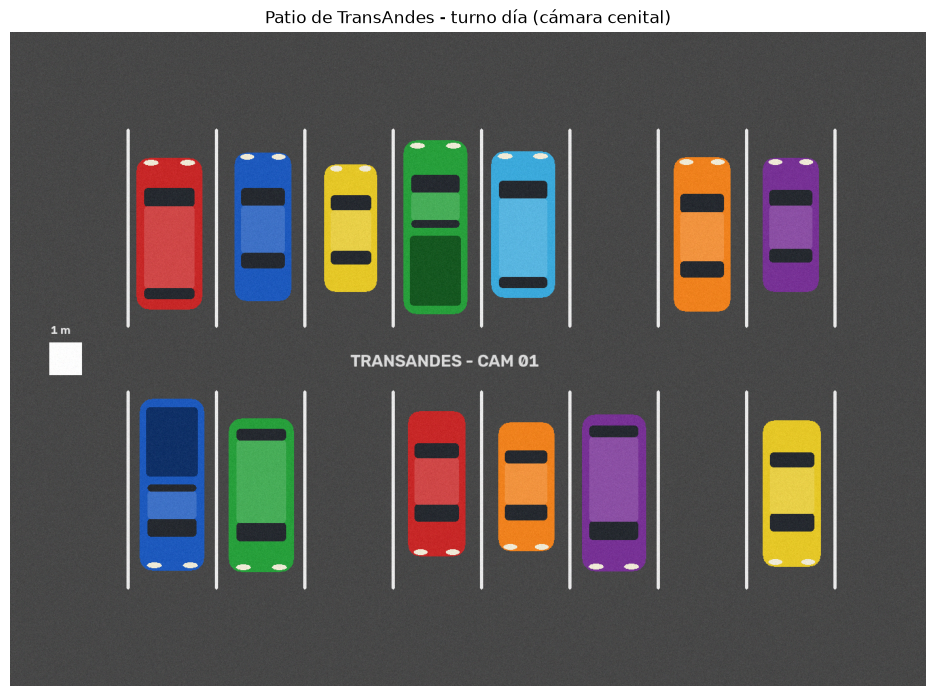

In [4]:
img = cv2.imread("imagenes/patio_turno_dia.png")     # devuelve una matriz NumPy

print("Tipo de dato   :", type(img))
print("Forma (shape)  :", img.shape)                # (alto, ancho, canales)
print("Tipo de píxel  :", img.dtype)                # uint8 -> 0 a 255
print("Total de datos :", img.size, "números")

alto, ancho, canales = img.shape
print(f"La imagen tiene {alto} filas, {ancho} columnas y {canales} canales")

mostrar(img, "Patio de TransAndes - turno día (cámara cenital)")

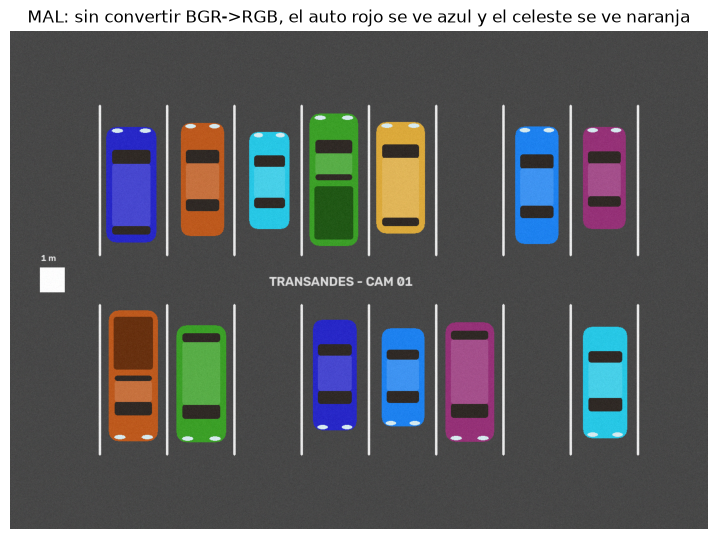

In [5]:
# Error típico: mostrar SIN convertir BGR -> RGB
plt.figure(figsize=(9, 6.5))
plt.imshow(img)
plt.title("MAL: sin convertir BGR->RGB, el auto rojo se ve azul y el celeste se ve naranja")
plt.axis("off")
plt.show()

In [6]:
# === Acceder a un píxel: img[fila, columna] -> img[y, x] ===
y, x = 300, 247                                   # techo del primer vehículo (plaza 1, fila superior)
pixel_auto = img[y, x]
pixel_asfalto = img[500, 1330]                    # asfalto del borde derecho
pixel_linea = img[300, 180]                       # línea blanca de la plaza

print("Píxel del auto    [B, G, R]:", pixel_auto)
print("Píxel del asfalto [B, G, R]:", pixel_asfalto)
print("Píxel de la línea [B, G, R]:", pixel_linea)

# Un píxel es un VECTOR: distancia euclidiana entre colores
def distancia(p, q):
    return np.linalg.norm(p.astype(float) - q.astype(float))

print(f"Distancia auto - asfalto  : {distancia(pixel_auto, pixel_asfalto):.1f}")
print(f"Distancia línea - asfalto : {distancia(pixel_linea, pixel_asfalto):.1f}")

Píxel del auto    [B, G, R]: [ 65  69 204]
Píxel del asfalto [B, G, R]: [73 72 75]
Píxel de la línea [B, G, R]: [242 241 238]
Distancia auto - asfalto  : 129.3
Distancia línea - asfalto : 289.3


Forma del recorte: (320, 135, 3)
Canal R de un bloque de 6x6 píxeles:
 [[208 211 210 205 211 204]
 [210 209 213 205 205 213]
 [207 208 205 204 205 201]
 [207 211 210 211 213 210]
 [206 217 202 215 210 215]
 [213 215 202 205 216 206]]


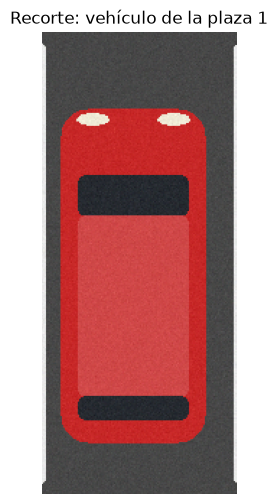

In [7]:
# === Recortar = SUBMATRIZ con slicing [y1:y2, x1:x2] ===
recorte = img[140:460, 180:315]                   # el primer vehículo con su plaza
print("Forma del recorte:", recorte.shape)

mini = img[298:304, 244:250, 2]                   # bloque 6x6 del canal R (índice 2)
print("Canal R de un bloque de 6x6 píxeles:\n", mini)

mostrar(recorte, "Recorte: vehículo de la plaza 1", tamano=(3, 6))

### Operaciones con matrices: ¡cuidado con el desbordamiento hacia abajo!

Los píxeles son `uint8` (0 a 255). Si **restamos** sin cuidado para simular el **atardecer**, `50 − 80` no da `0` sino `226` (da la vuelta). `cv2.subtract` *satura* en 0.

NumPy  50 - 80 = 226
OpenCV 50 - 80 = 0


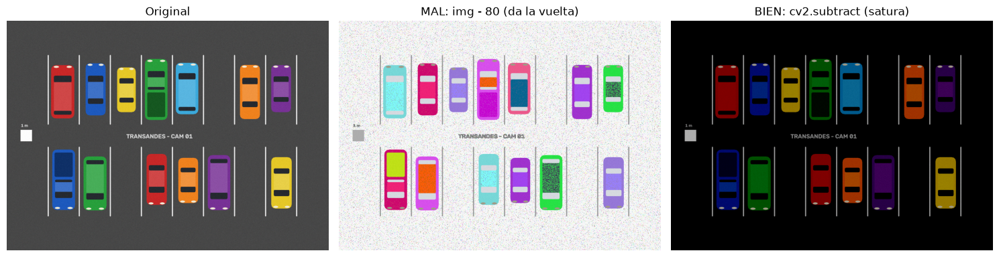

In [8]:
a = np.array([[50]], dtype=np.uint8)
b = np.array([[80]], dtype=np.uint8)
print("NumPy  50 - 80 =", (a - b)[0, 0])                # 50 - 80 + 256 = 226
print("OpenCV 50 - 80 =", cv2.subtract(a, b)[0, 0])     # satura en 0

oscura_mal  = img - 80                                   # con desbordamiento
oscura_bien = cv2.subtract(img, np.full(img.shape, 80, dtype=np.uint8))

mostrar_varias([img, oscura_mal, oscura_bien],
               ["Original", "MAL: img - 80 (da la vuelta)", "BIEN: cv2.subtract (satura)"])

🧪 **Pruébalo tú:** cambia `y, x` en la celda del píxel a `y=700, x=1127` (un vehículo amarillo de la fila inferior). ¿Qué canales tienen los valores más altos? ¿Por qué el amarillo es "rojo + verde"?

---
## Paso 3 · Representaciones: escala de grises, canales y HSV

- **Gris**: un canal de luminosidad. `Gris = 0.299·R + 0.587·G + 0.114·B`.
- **HSV**: separa **H (tono/color)**, **S (saturación)** y **V (brillo)**. El asfalto y las líneas son **grises** (S ≈ 0), mientras que la pintura de los vehículos tiene **mucha saturación**. Esa diferencia es la que usaremos para segmentar.

> En OpenCV H va de **0 a 179**: rojo ≈ 0, naranja ≈ 14, amarillo ≈ 25, verde ≈ 65, celeste ≈ 99, azul ≈ 109, morado ≈ 141.

Forma en gris: (1000, 1400)
Gris a mano: 108.9 | OpenCV: 109


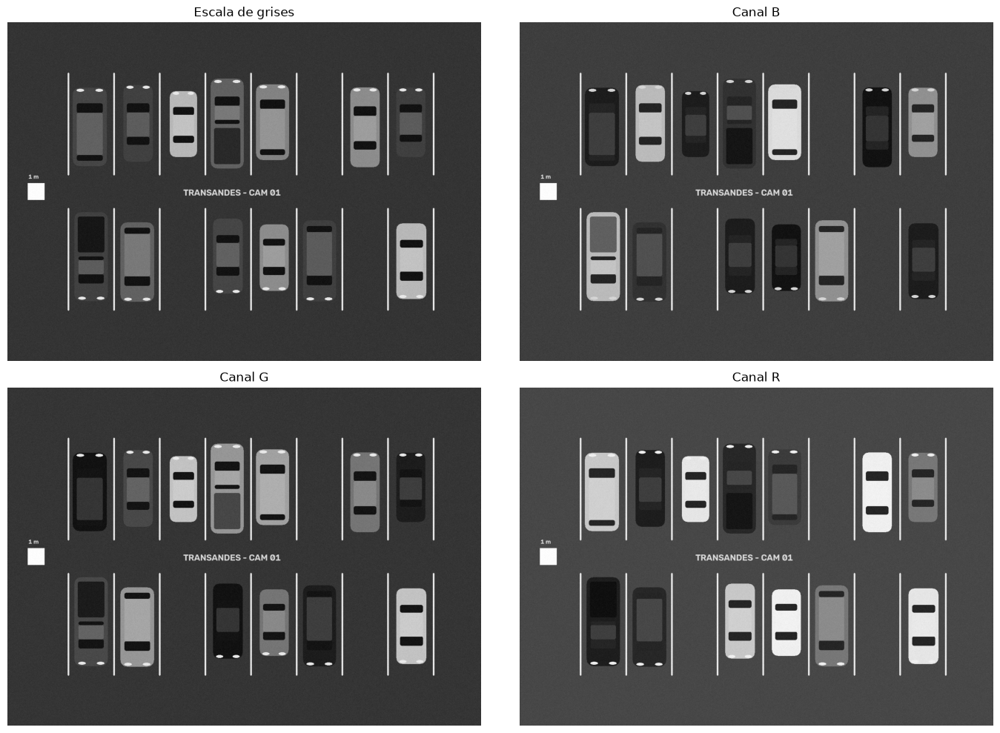

In [9]:
gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
print("Forma en gris:", gris.shape)

b, g, r = img[300, 247].astype(float)
print(f"Gris a mano: {0.299*r + 0.587*g + 0.114*b:.1f} | OpenCV: {gris[300, 247]}")

B, G, R = cv2.split(img)
mostrar_varias([gris, B, G, R], ["Escala de grises", "Canal B", "Canal G", "Canal R"],
               columnas=2, tamano=(14, 5))

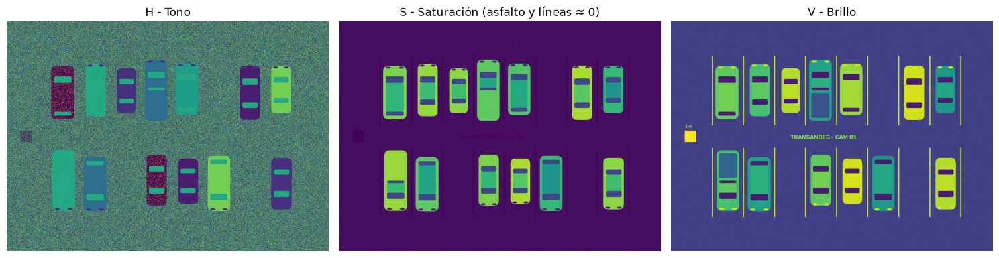

HSV del auto rojo    : [  1 174 204]
HSV del asfalto      : [170  10  75]
HSV de la línea      : [ 98   4 242]


In [10]:
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
H, S, V = cv2.split(hsv)

mostrar_varias([H, S, V], ["H - Tono", "S - Saturación (asfalto y líneas ≈ 0)", "V - Brillo"],
               cmap="viridis")

print("HSV del auto rojo    :", hsv[300, 247])
print("HSV del asfalto      :", hsv[500, 1330])
print("HSV de la línea      :", hsv[300, 180])

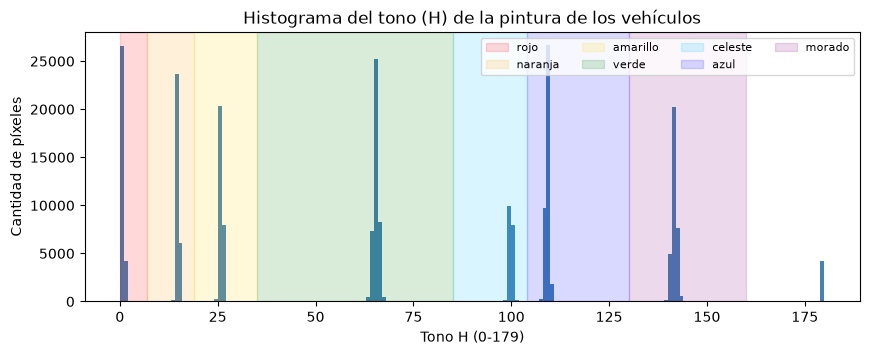

In [11]:
# Histograma del tono SOLO de los píxeles con color (saturación alta): ¿qué colores tiene la flota?
tonos = H[S > 80]
plt.figure(figsize=(10, 3.5))
plt.hist(tonos, bins=180, range=(0, 180), color="steelblue")
rangos = [("rojo", 0, 7, "red"), ("naranja", 7, 19, "orange"), ("amarillo", 19, 35, "gold"),
          ("verde", 35, 85, "green"), ("celeste", 85, 104, "deepskyblue"), ("azul", 104, 130, "blue"),
          ("morado", 130, 160, "purple")]
for nombre, a_, b_, col in rangos:
    plt.axvspan(a_, b_, color=col, alpha=0.15, label=nombre)
plt.title("Histograma del tono (H) de la pintura de los vehículos")
plt.xlabel("Tono H (0-179)")
plt.ylabel("Cantidad de píxeles")
plt.legend(ncol=4, fontsize=8)
plt.show()

### ❓ Pregunta 2
¿Por qué el canal **S (saturación)** separa tan bien los vehículos del asfalto y de las líneas blancas? ¿Qué pasaría con un vehículo **blanco, negro o plateado**?

*Escribe tu respuesta aquí:*

---
## Paso 4 · Filtrado y detección de bordes

Un **filtro** recorre la imagen con un **kernel** (una matriz pequeña) y en cada posición multiplica y suma los vecinos (**convolución**).

- **Suavizado** (`blur`, `GaussianBlur`, `medianBlur`): quita el ruido del sensor.
- **Bordes** (`Canny`, `Sobel`, `Laplacian`): resaltan los cambios bruscos de intensidad → el contorno de cada vehículo, parabrisas y líneas.

Kernel promedio 5x5 (cada valor = 1/25):
 [[0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]]


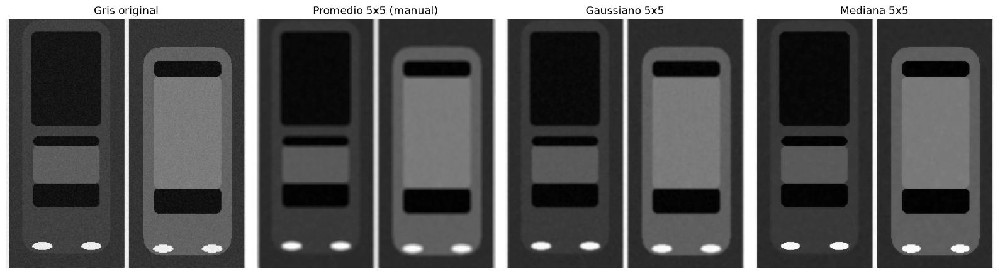

In [12]:
kernel_promedio = np.ones((5, 5), np.float32) / 25        # promedio 5x5
print("Kernel promedio 5x5 (cada valor = 1/25):\n", np.round(kernel_promedio, 3))

suave_manual = cv2.filter2D(gris, -1, kernel_promedio)
suave_gauss  = cv2.GaussianBlur(gris, (5, 5), 0)
suave_median = cv2.medianBlur(gris, 5)

zona = (slice(560, 840), slice(180, 450))                 # zoom a la fila inferior izquierda
mostrar_varias([gris[zona], suave_manual[zona], suave_gauss[zona], suave_median[zona]],
               ["Gris original", "Promedio 5x5 (manual)", "Gaussiano 5x5", "Mediana 5x5"],
               columnas=4, tamano=(16, 4.5))

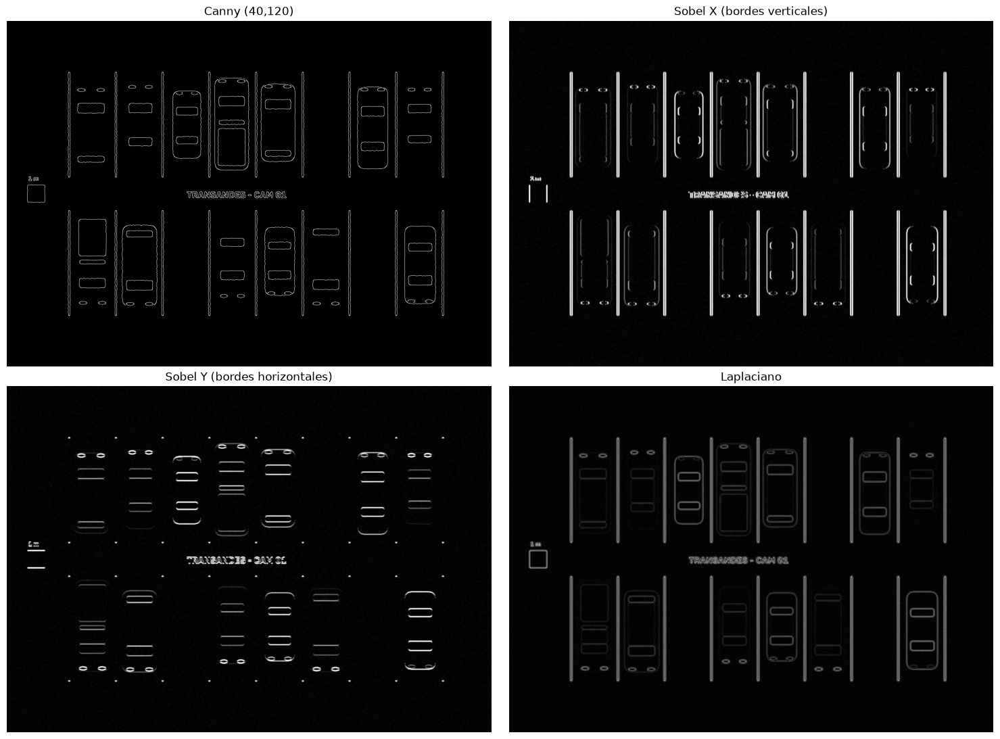

In [13]:
bordes = cv2.Canny(suave_gauss, 40, 120)

sobel_x = cv2.Sobel(suave_gauss, cv2.CV_64F, 1, 0, ksize=3)     # cambios horizontales
sobel_y = cv2.Sobel(suave_gauss, cv2.CV_64F, 0, 1, ksize=3)     # cambios verticales
magnitud = cv2.convertScaleAbs(np.sqrt(sobel_x**2 + sobel_y**2))
laplaciano = cv2.convertScaleAbs(cv2.Laplacian(suave_gauss, cv2.CV_64F, ksize=3))

mostrar_varias([bordes, cv2.convertScaleAbs(sobel_x), cv2.convertScaleAbs(sobel_y), laplaciano],
               ["Canny (40,120)", "Sobel X (bordes verticales)", "Sobel Y (bordes horizontales)", "Laplaciano"],
               columnas=2, tamano=(15, 5.5))

🧪 **Pruébalo tú:** observa que **Sobel X** resalta los lados largos de los autos y las líneas de las plazas (son verticales), mientras **Sobel Y** resalta parabrisas y frentes. Cambia Canny a `(10, 30)` y a `(150, 300)`. ¿Qué umbral muestra el ruido del asfalto?

---
## Paso 5 · Transformaciones geométricas (y el problema del turno noche)

Las transformaciones mueven píxeles usando **matrices**: escalado (`resize`), volteo (`flip`), traslación y rotación (`warpAffine`). La rotación usa una matriz 2×3:

```
M = | cosθ   sinθ   tx |
    | -sinθ  cosθ   ty |
```

Matriz de rotación 2x3:
 [[   0.94     0.342 -128.795]
 [  -0.342    0.94   269.568]]
Tamaño original: (1000, 1400, 3) | reducida: (500, 700, 3)


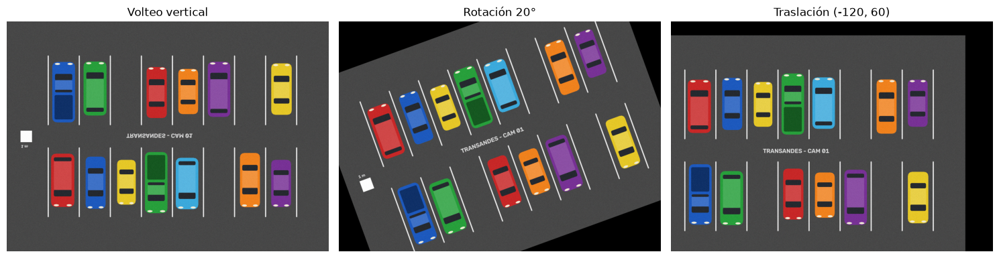

In [14]:
pequena = cv2.resize(img, None, fx=0.5, fy=0.5)
volteada = cv2.flip(img, 0)                                # 0 = espejo vertical

centro = (ancho // 2, alto // 2)
M = cv2.getRotationMatrix2D(centro, 20, 1.0)               # 20° antihorario
print("Matriz de rotación 2x3:\n", np.round(M, 3))
rotada = cv2.warpAffine(img, M, (ancho, alto))

T = np.float32([[1, 0, -120], [0, 1, 60]])                 # 120 px a la izquierda, 60 abajo
trasladada = cv2.warpAffine(img, T, (ancho, alto))

print("Tamaño original:", img.shape, "| reducida:", pequena.shape)
mostrar_varias([volteada, rotada, trasladada], ["Volteo vertical", "Rotación 20°", "Traslación (-120, 60)"])

### 🌙 El problema del turno noche

Un camión golpeó el poste: la cámara quedó **girada** y además es de noche. Esta vez **nadie nos dice el ángulo**: lo calcularemos con el **patrón de 1 m**, que siempre está alineado con el patio.

Orden de corrección:
1. **Luz**: igualar el brillo del asfalto al del turno día (mediana del canal V).
2. **Giro**: medir el ángulo del patrón con `minAreaRect` y rotar en sentido contrario.

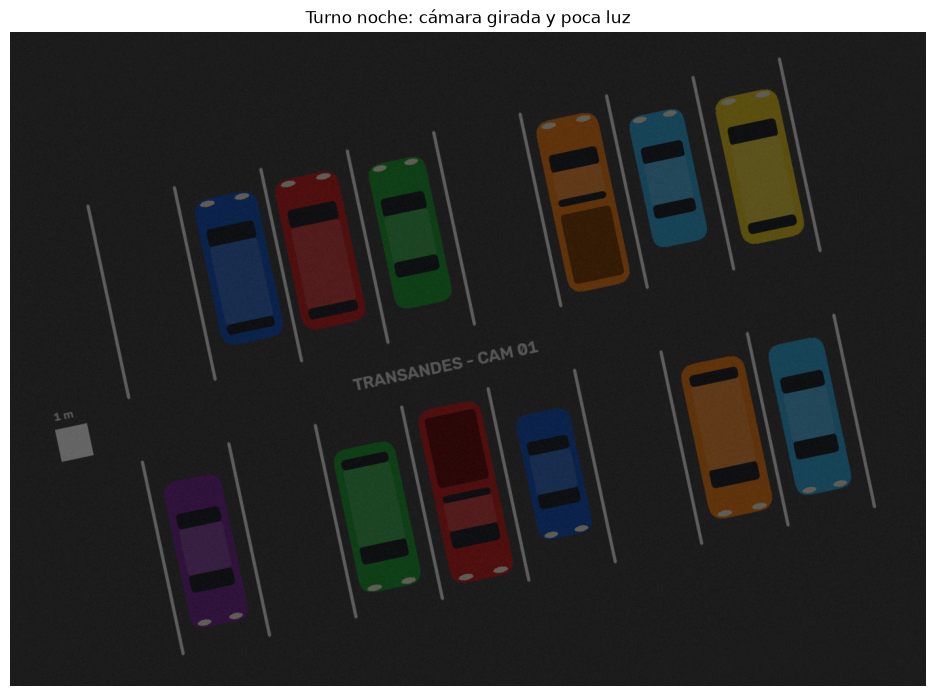

Brillo asfalto día = 74.0, noche = 29.0 -> factor = 2.55


In [15]:
noche = cv2.imread("imagenes/patio_turno_noche.png")
mostrar(noche, "Turno noche: cámara girada y poca luz")

brillo_dia   = np.median(cv2.cvtColor(img,   cv2.COLOR_BGR2HSV)[:, :, 2])
brillo_noche = np.median(cv2.cvtColor(noche, cv2.COLOR_BGR2HSV)[:, :, 2])
factor = brillo_dia / brillo_noche
print(f"Brillo asfalto día = {brillo_dia}, noche = {brillo_noche} -> factor = {factor:.2f}")

noche_iluminada = cv2.convertScaleAbs(noche, alpha=factor, beta=0)     # píxel * factor (satura en 255)

In [16]:
LADO_PATRON_M = 1.0          # el patrón mide 1 m x 1 m

def buscar_patron(imagen_bgr):
    """Busca el cuadrado blanco. Devuelve (lado_px, angulo_grados) o (None, None)."""
    hsv_img = cv2.cvtColor(imagen_bgr, cv2.COLOR_BGR2HSV)
    blanco = cv2.inRange(hsv_img, np.array([0, 0, 200]), np.array([179, 40, 255]))   # claro y sin color
    cnts, _ = cv2.findContours(blanco, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    candidatos = []
    for c in cnts:
        (_, _), (w, h), ang = cv2.minAreaRect(c)
        if w * h > 400 and 0.8 < w / h < 1.25 and cv2.contourArea(c) > 0.85 * w * h:
            candidatos.append((w * h, (w + h) / 2 + 1, ang))     # cuadrado y relleno (no líneas ni letras)
    if not candidatos:
        return None, None
    _, lado_px, ang = max(candidatos)                            # el cuadrado más grande
    ang = ((ang + 45) % 90) - 45                                 # un cuadrado se repite cada 90°: dejamos el ángulo en [-45, 45)
    return lado_px, ang

lado_px, angulo = buscar_patron(noche_iluminada)
print(f"Patrón encontrado: lado = {lado_px:.1f} px, ángulo de la cámara = {angulo:.1f}°")
print("En la foto ORIGINAL de noche (sin iluminar):", buscar_patron(noche))

Patrón encontrado: lado = 50.6 px, ángulo de la cámara = -12.0°
En la foto ORIGINAL de noche (sin iluminar): (None, None)


Ángulo del patrón después de corregir: 0.0 °


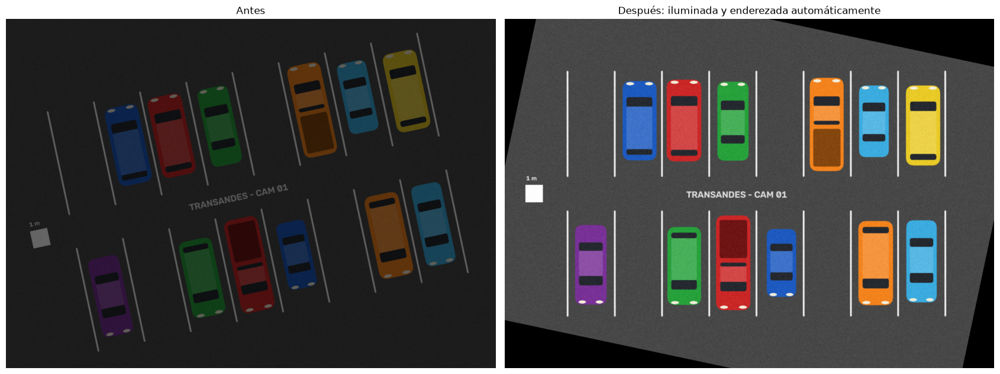

In [17]:
h2, w2 = noche.shape[:2]
M_corr = cv2.getRotationMatrix2D((w2 // 2, h2 // 2), angulo, 1.0)       # rotación que endereza
noche_corregida = cv2.warpAffine(noche_iluminada, M_corr, (w2, h2), borderValue=(0, 0, 0))

print("Ángulo del patrón después de corregir:", round(buscar_patron(noche_corregida)[1], 1), "°")
mostrar_varias([noche, noche_corregida], ["Antes", "Después: iluminada y enderezada automáticamente"],
               columnas=2, tamano=(17, 6.5))

---
## Paso 6 · Segmentación: separar los vehículos del asfalto

**Segmentar** = crear una **máscara binaria** (`255` vehículo, `0` fondo). Comparamos:
1. **Otsu en gris**: corte automático de brillo.
2. **Rango HSV**: saturación alta (la pintura) y un brillo mínimo.

Umbral elegido por Otsu: 124.0


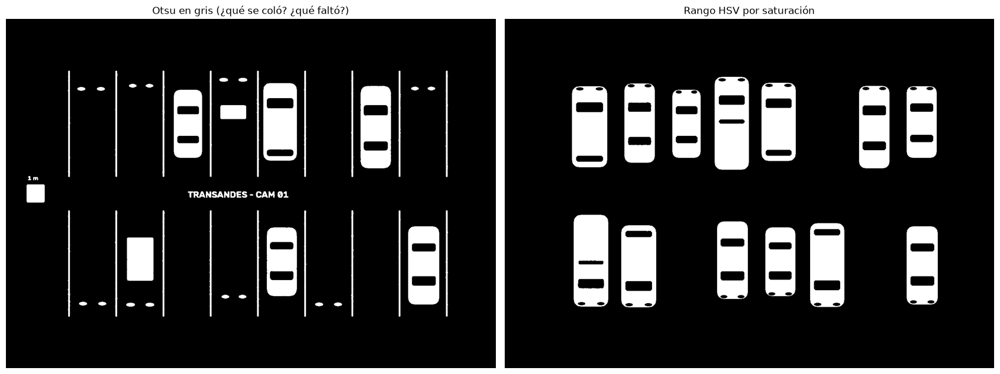

In [18]:
suave_color = cv2.medianBlur(img, 5)        # preprocesamiento: la MEDIANA quita el ruido sin engordar los bordes
hsv_suave = cv2.cvtColor(suave_color, cv2.COLOR_BGR2HSV)

umbral, mascara_otsu = cv2.threshold(suave_gauss, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print("Umbral elegido por Otsu:", umbral)

S_MIN, V_MIN = 80, 40
mascara_hsv = cv2.inRange(hsv_suave, np.array([0, S_MIN, V_MIN]), np.array([179, 255, 255]))

mostrar_varias([mascara_otsu, mascara_hsv], ["Otsu en gris (¿qué se coló? ¿qué faltó?)", "Rango HSV por saturación"],
               columnas=2, tamano=(17, 6.5))

> Con Otsu entran las **líneas, el patrón y el texto**, y los autos **oscuros** (azul, morado) pueden perderse. Con HSV solo queda la pintura. Los **parabrisas** (oscuros y sin color) quedan como huecos; los rellenaremos.

### Morfología: limpiar la máscara
- **Apertura** (`MORPH_OPEN`): borra puntos sueltos.
- **Cierre** (`MORPH_CLOSE`): rellena huecos pequeños. Los huecos grandes (parabrisas) se resuelven al tomar solo el **contorno externo**.

Los vehículos ocupan el 18.9 % de la foto


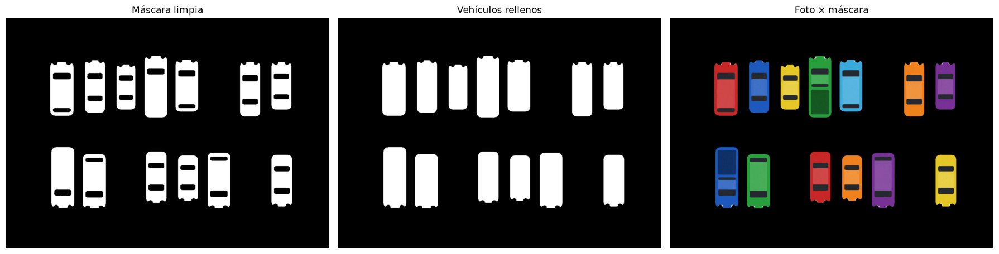

In [19]:
kernel_morf = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))

def limpiar(mascara_bin):
    m = cv2.morphologyEx(mascara_bin, cv2.MORPH_OPEN, kernel_morf)
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, kernel_morf, iterations=2)
    return m

mascara = limpiar(mascara_hsv)

# Rellenar cada vehículo completo dibujando sus contornos externos
cnts_tmp, _ = cv2.findContours(mascara, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
mascara_llena = np.zeros_like(mascara)
cv2.drawContours(mascara_llena, cnts_tmp, -1, 255, -1)

porcentaje = 100 * np.count_nonzero(mascara_llena) / mascara_llena.size
print(f"Los vehículos ocupan el {porcentaje:.1f} % de la foto")

solo_autos = cv2.bitwise_and(img, img, mask=mascara_llena)
mostrar_varias([mascara, mascara_llena, solo_autos], ["Máscara limpia", "Vehículos rellenos", "Foto × máscara"],
               columnas=3, tamano=(18, 4.5))

---
## Paso 7 · Detección: cajas **rotadas** y medidas en metros

En el caso guiado se usó `boundingRect` (caja recta). Un vehículo puede estar **girado**, y una caja recta lo mediría más grande. Por eso usamos `minAreaRect`, que devuelve el **rectángulo más pequeño** que lo encierra, con su ángulo:

| Medida | Función | Para qué |
|---|---|---|
| Área | `cv2.contourArea` | Descartar ruido |
| Caja rotada | `cv2.minAreaRect` → `cv2.boxPoints` | **Largo y ancho reales** del vehículo |
| Centroide | `cv2.moments` | Ubicar el vehículo y ordenar por plaza |
| Rectangularidad | `Área / (largo·ancho)` | 1 = rectángulo perfecto |

Regiones encontradas: 13
Vehículos detectados: 13


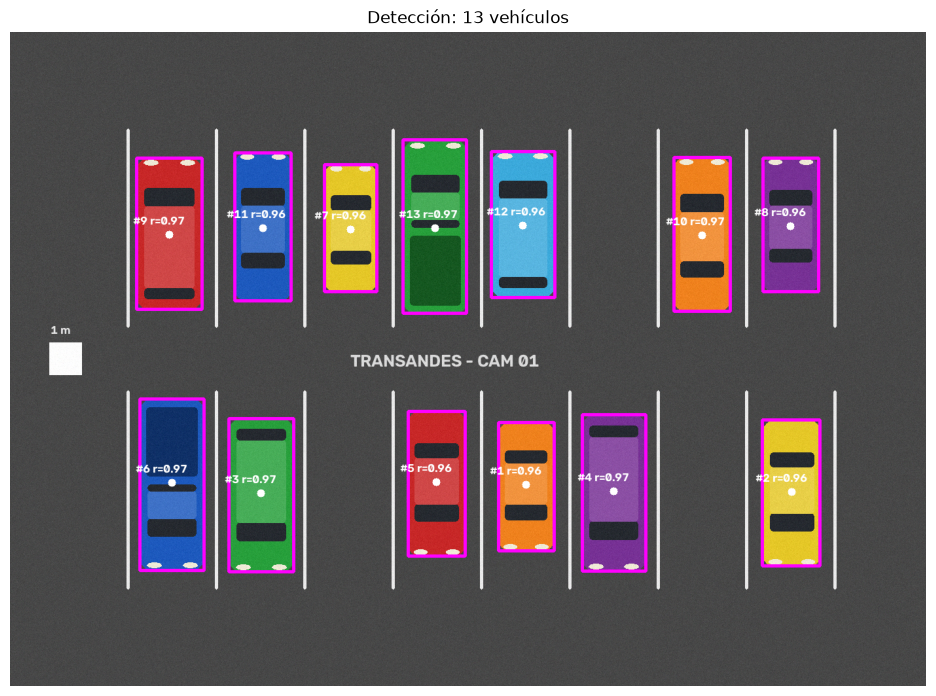

In [20]:
contornos, _ = cv2.findContours(mascara, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
print("Regiones encontradas:", len(contornos))

AREA_MINIMA = 5000                                      # px²: menos que esto no es un vehículo
vehiculos = [c for c in contornos if cv2.contourArea(c) > AREA_MINIMA]
print("Vehículos detectados:", len(vehiculos))

detecciones = img.copy()
for i, c in enumerate(vehiculos, start=1):
    rect = cv2.minAreaRect(c)                           # ((cx, cy), (w, h), ángulo)
    caja = cv2.boxPoints(rect).astype(int)              # 4 esquinas de la caja rotada
    m = cv2.moments(c)
    cx, cy = int(m["m10"] / m["m00"]), int(m["m01"] / m["m00"])
    rectangularidad = cv2.contourArea(c) / (rect[1][0] * rect[1][1])

    cv2.drawContours(detecciones, [caja], -1, (255, 0, 255), 3)
    cv2.circle(detecciones, (cx, cy), 6, (255, 255, 255), -1)
    cv2.putText(detecciones, f"#{i} r={rectangularidad:.2f}", (cx - 55, cy - 15), FUENTE, 0.6, (255, 255, 255), 2)

mostrar(detecciones, f"Detección: {len(vehiculos)} vehículos")

### Calibración: de píxeles a metros

Ya tenemos `buscar_patron()`: si el cuadrado de 1 m mide `L` píxeles de lado, entonces `px_por_m = L / 1.0`.

In [21]:
def calcular_escala(imagen_bgr):
    lado_px, _ = buscar_patron(imagen_bgr)
    return None if lado_px is None else lado_px / LADO_PATRON_M

px_por_m = calcular_escala(img)
print(f"Escala: {px_por_m:.2f} píxeles por metro  ->  1 píxel = {100 / px_por_m:.1f} cm")

Escala: 50.00 píxeles por metro  ->  1 píxel = 2.0 cm


---
## Paso 8 · Reconocimiento de patrones: ¿qué tipo de vehículo es? ¿es SUV?

Para cada vehículo extraemos un **vector de características**:

| Característica | Cómo se calcula |
|---|---|
| `largo_m`, `ancho_m` | Lados de la caja rotada (`minAreaRect`) ÷ escala |
| `relacion` | largo / ancho (las SUV son más "cuadradas" que los sedanes) |
| `area_m2` | Área del contorno ÷ escala² |
| `color` | Tono **medio circular** de la pintura (el rojo está en 0 y en 179: un promedio simple fallaría) |

Luego aplicamos la **norma** con `if / elif / else` y guardamos todo en una **lista de diccionarios**.

In [22]:
NORMA = {
    "largo_pickup_m": 5.05,     # desde este largo es PICKUP (tiene caja)
    "ancho_suv_m": 1.83,        # desde este ancho es SUV
    "largo_compacto_m": 4.25,   # por debajo de este largo es COMPACTO
}
RANGOS_COLOR = [("rojo", 0, 7), ("naranja", 7, 19), ("amarillo", 19, 35), ("verde", 35, 85),
                ("celeste", 85, 104), ("azul", 104, 130), ("morado", 130, 160), ("rojo", 160, 180)]

def nombre_color(h):
    for nombre, a_, b_ in RANGOS_COLOR:
        if a_ <= h < b_:
            return nombre
    return "?"

def tono_medio_circular(tonos_h):
    """Promedia ángulos: H (0-179) -> grados (x2) -> vectores (cos, sin) -> promedio -> ángulo."""
    rad = np.deg2rad(tonos_h.astype(float) * 2)
    ang = np.rad2deg(np.arctan2(np.sin(rad).mean(), np.cos(rad).mean())) % 360
    return ang / 2

def extraer_caracteristicas(imagen_bgr, contorno, escala):
    """Devuelve un diccionario con las características de UN vehículo."""
    (cx, cy), (w, h), _ = cv2.minAreaRect(contorno)
    largo_m = (max(w, h) + 1) / escala                # +1: el borde también es un píxel
    ancho_m = (min(w, h) + 1) / escala

    hsv_img = cv2.cvtColor(imagen_bgr, cv2.COLOR_BGR2HSV)
    mascara_uno = np.zeros(imagen_bgr.shape[:2], np.uint8)
    cv2.drawContours(mascara_uno, [contorno], -1, 255, -1)
    interior = cv2.erode(mascara_uno, np.ones((9, 9), np.uint8))
    pintura = (interior == 255) & (hsv_img[:, :, 1] > 80)
    tono = tono_medio_circular(hsv_img[:, :, 0][pintura])

    return {"cx": int(cx), "cy": int(cy),
            "largo_m": round(float(largo_m), 2), "ancho_m": round(float(ancho_m), 2),
            "relacion": round(float(largo_m / ancho_m), 2),
            "area_m2": round(float(cv2.contourArea(contorno) / escala**2), 2),
            "tono_h": round(float(tono), 1), "color": nombre_color(tono)}

def clasificar(f):
    """Aplica la norma. Devuelve (tipo, motivo)."""
    if f["largo_m"] >= NORMA["largo_pickup_m"]:
        return "PICKUP", f"largo ≥ {NORMA['largo_pickup_m']} m"
    elif f["ancho_m"] >= NORMA["ancho_suv_m"]:
        return "SUV", f"ancho ≥ {NORMA['ancho_suv_m']} m"
    elif f["largo_m"] < NORMA["largo_compacto_m"]:
        return "COMPACTO", f"largo < {NORMA['largo_compacto_m']} m"
    else:
        return "SEDAN", "medidas intermedias"

f1 = extraer_caracteristicas(img, vehiculos[0], px_por_m)
print("Características:", f1, "->", clasificar(f1))

Características: {'cx': 788, 'cy': 695, 'largo_m': 3.94, 'ancho_m': 1.72, 'relacion': 2.29, 'area_m2': 6.39, 'tono_h': 14.2, 'color': 'naranja'} -> ('COMPACTO', 'largo < 4.25 m')


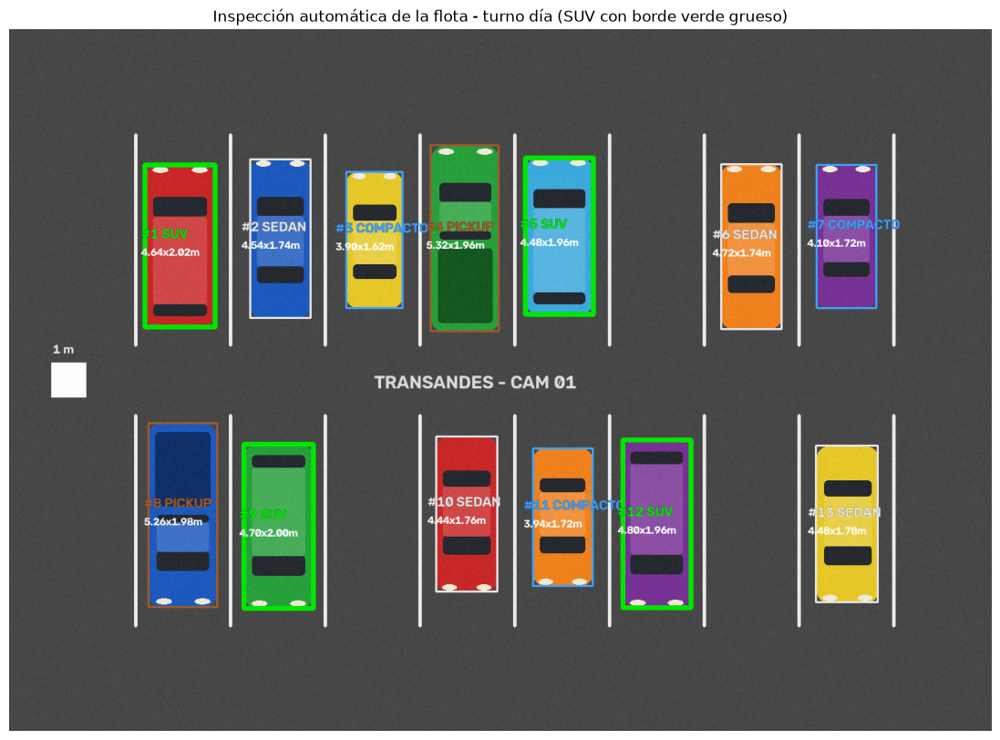

,id,cx,cy,largo_m,ancho_m,relacion,area_m2,tono_h,color,tipo,es_suv,motivo
0,1,243,308,4.64,2.02,2.30,8.92,179.9,rojo,SUV,True,ancho ≥ 1.83 m
1,2,386,298,4.54,1.74,2.61,7.50,108.8,azul,SEDAN,False,medidas intermedias
2,3,520,300,3.90,1.62,2.41,5.97,25.3,amarillo,COMPACTO,False,largo < 4.25 m
3,4,649,298,5.32,1.96,2.71,9.96,65.1,verde,PICKUP,False,largo ≥ 5.05 m
4,5,783,294,4.48,1.96,2.29,8.33,99.5,celeste,SUV,True,ancho ≥ 1.83 m
5,6,1057,309,4.72,1.74,2.71,7.80,14.2,naranja,SEDAN,False,medidas intermedias
6,7,1192,295,4.10,1.72,2.38,6.68,141.0,morado,COMPACTO,False,largo < 4.25 m
7,8,247,692,5.26,1.98,2.66,9.95,108.8,azul,PICKUP,False,largo ≥ 5.05 m
8,9,383,708,4.70,2.00,2.35,8.95,65.1,verde,SUV,True,ancho ≥ 1.83 m
9,10,651,690,4.44,1.76,2.52,7.42,179.9,rojo,SEDAN,False,medidas intermedias


In [23]:
COLORES_TIPO = {"SUV": (0, 230, 0), "PICKUP": (40, 90, 160), "SEDAN": (230, 230, 230), "COMPACTO": (255, 160, 60)}

def ordenar_por_plaza(cnts):
    """Fila superior primero, de izquierda a derecha (usa el centro de la caja rotada)."""
    return sorted(cnts, key=lambda c: (cv2.minAreaRect(c)[0][1] // 400, cv2.minAreaRect(c)[0][0]))

vehiculos = ordenar_por_plaza(vehiculos)
registros = []
anotada = img.copy()

for i, c in enumerate(vehiculos, start=1):
    feats = extraer_caracteristicas(img, c, px_por_m)
    tipo, motivo = clasificar(feats)
    registros.append({"id": i, **feats, "tipo": tipo, "es_suv": tipo == "SUV", "motivo": motivo})

    caja = cv2.boxPoints(cv2.minAreaRect(c)).astype(int)
    grosor = 6 if tipo == "SUV" else 2                     # las SUV resaltan
    cv2.drawContours(anotada, [caja], -1, COLORES_TIPO[tipo], grosor)
    cx, cy = feats["cx"], feats["cy"]
    cv2.putText(anotada, f"#{i} {tipo}", (cx - 55, cy - 10), FUENTE, 0.65, (0, 0, 0), 4)
    cv2.putText(anotada, f"#{i} {tipo}", (cx - 55, cy - 10), FUENTE, 0.65, COLORES_TIPO[tipo], 2)
    cv2.putText(anotada, f"{feats['largo_m']:.2f}x{feats['ancho_m']:.2f}m", (cx - 55, cy + 15),
                FUENTE, 0.5, (255, 255, 255), 2)

reporte = pd.DataFrame(registros)
mostrar(anotada, "Inspección automática de la flota - turno día (SUV con borde verde grueso)", tamano=(14, 10))
reporte

--- Turno día ---
tipo
SUV         4
SEDAN       4
COMPACTO    3
PICKUP      2 

SUV detectadas: #1 (rojo), #5 (celeste), #9 (verde), #12 (morado)
❌ NO alcanza para el contrato. Faltan: {'SUV': 1}


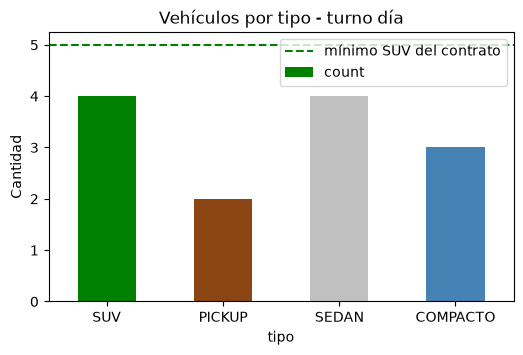

Guardado en la carpeta resultados/


In [24]:
# === Resumen de la flota y decisión del contrato ===
CONTRATO = {"SUV": 5, "PICKUP": 2}          # mínimos exigidos por la minera

def decidir_contrato(tabla, nombre):
    conteo = tabla["tipo"].value_counts()
    print(f"--- {nombre} ---")
    print(conteo.to_string(), "\n")
    print("SUV detectadas:", ", ".join(f"#{r.id} ({r.color})" for r in tabla[tabla["es_suv"]].itertuples()))
    faltan = {t: int(n - conteo.get(t, 0)) for t, n in CONTRATO.items() if conteo.get(t, 0) < n}
    if faltan:
        print("❌ NO alcanza para el contrato. Faltan:", faltan)
    else:
        print("✅ La flota CUMPLE el contrato minero.")
    return conteo

conteo_dia = decidir_contrato(reporte, "Turno día")

orden = ["SUV", "PICKUP", "SEDAN", "COMPACTO"]
conteo_dia.reindex(orden, fill_value=0).plot(kind="bar", color=["green", "saddlebrown", "silver", "steelblue"],
                                             figsize=(6, 3.5), rot=0, title="Vehículos por tipo - turno día")
plt.axhline(CONTRATO["SUV"], color="green", ls="--", label="mínimo SUV del contrato")
plt.ylabel("Cantidad")
plt.legend()
plt.show()

reporte.to_csv("resultados/reporte_turno_dia.csv", index=False, encoding="utf-8-sig")
cv2.imwrite("resultados/turno_dia_inspeccionado.png", anotada)
print("Guardado en la carpeta resultados/")

In [25]:
# ¿Acertó el sistema? Comparamos con la verdad del simulador (vehículo más cercano por posición)
def comparar_con_verdad(tabla, verdad):
    filas = []
    for r in tabla.itertuples():
        d = np.hypot(verdad["cx"] - r.cx, verdad["cy"] - r.cy)
        v = verdad.loc[d.idxmin()]
        filas.append({"id": r.id, "tipo_sistema": r.tipo, "tipo_real": v["tipo_real"],
                      "largo_med": r.largo_m, "largo_real": v["largo_real"],
                      "ancho_med": r.ancho_m, "ancho_real": v["ancho_real"],
                      "color_sistema": r.color, "color_real": v["pintura"]})
    comp = pd.DataFrame(filas)
    comp["acierto"] = comp["tipo_sistema"] == comp["tipo_real"]
    return comp

comp_dia = comparar_con_verdad(reporte, verdad_dia)
print(f"Aciertos de tipo: {comp_dia['acierto'].mean():.0%} | error medio de largo: "
      f"{(comp_dia['largo_med'] - comp_dia['largo_real']).abs().mean() * 100:.1f} cm")
comp_dia

Aciertos de tipo: 100% | error medio de largo: 1.9 cm


,id,tipo_sistema,tipo_real,largo_med,largo_real,ancho_med,ancho_real,color_sistema,color_real,acierto
0,1,SUV,SUV,4.64,4.63,2.02,1.99,rojo,rojo,True
1,2,SEDAN,SEDAN,4.54,4.52,1.74,1.73,azul,azul,True
2,3,COMPACTO,COMPACTO,3.90,3.87,1.62,1.60,amarillo,amarillo,True
3,4,PICKUP,PICKUP,5.32,5.30,1.96,1.94,verde,verde,True
4,5,SUV,SUV,4.48,4.46,1.96,1.93,celeste,celeste,True
5,6,SEDAN,SEDAN,4.72,4.70,1.74,1.72,naranja,naranja,True
6,7,COMPACTO,COMPACTO,4.10,4.08,1.72,1.69,morado,morado,True
7,8,PICKUP,PICKUP,5.26,5.25,1.98,1.96,azul,azul,True
8,9,SUV,SUV,4.70,4.68,2.00,1.97,verde,verde,True
9,10,SEDAN,SEDAN,4.44,4.42,1.76,1.74,rojo,rojo,True


### ❓ Pregunta 3
El sedán más ancho mide unos 1.78 m y la SUV más angosta 1.88 m. Cambia `NORMA["ancho_suv_m"]` a **1.75** y vuelve a ejecutar las celdas del Paso 8. ¿Qué pasa con el conteo de SUV? ¿Qué consecuencias tendría para la empresa **firmar el contrato** con ese error?

*Escribe tu respuesta aquí:*

---
## Paso 9 · El sistema completo: `inspeccionar()` y el reto del turno noche

In [26]:
ESCALA_POR_DEFECTO = 40      # px/m de la instalación antigua (la cámara estaba más alta)

def inspeccionar(imagen_bgr, nombre="patio"):
    """Pipeline completo: suavizar -> segmentar -> detectar -> medir -> clasificar."""
    escala = calcular_escala(imagen_bgr)
    if escala is None:
        print(f"⚠️ [{nombre}] No se encontró el patrón de 1 m. Se usa {ESCALA_POR_DEFECTO} px/m por defecto.")
        escala = ESCALA_POR_DEFECTO

    hsv_img = cv2.cvtColor(cv2.medianBlur(imagen_bgr, 5), cv2.COLOR_BGR2HSV)
    m = limpiar(cv2.inRange(hsv_img, np.array([0, S_MIN, V_MIN]), np.array([179, 255, 255])))
    cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cnts = ordenar_por_plaza([c for c in cnts if cv2.contourArea(c) > AREA_MINIMA])

    filas, salida = [], imagen_bgr.copy()
    for i, c in enumerate(cnts, start=1):
        f = extraer_caracteristicas(imagen_bgr, c, escala)
        tipo, motivo = clasificar(f)
        filas.append({"id": i, **f, "tipo": tipo, "es_suv": tipo == "SUV", "motivo": motivo})
        caja = cv2.boxPoints(cv2.minAreaRect(c)).astype(int)
        cv2.drawContours(salida, [caja], -1, COLORES_TIPO[tipo], 6 if tipo == "SUV" else 2)
        cv2.putText(salida, f"#{i} {tipo}", (f["cx"] - 55, f["cy"]), FUENTE, 0.65, (0, 0, 0), 4)
        cv2.putText(salida, f"#{i} {tipo}", (f["cx"] - 55, f["cy"]), FUENTE, 0.65, COLORES_TIPO[tipo], 2)

    tabla = pd.DataFrame(filas)
    print(f"[{nombre}] escala={escala:.1f} px/m | vehículos={len(tabla)} |",
          {k: int(v) for k, v in tabla["tipo"].value_counts().items()} if len(tabla) else "sin detecciones")
    return tabla, salida

_ = inspeccionar(img, "turno día")      # debe dar lo mismo que el Paso 8

[turno día] escala=50.0 px/m | vehículos=13 | {'SUV': 4, 'SEDAN': 4, 'COMPACTO': 3, 'PICKUP': 2}


### 🌙 Reto: ¿qué pasa si analizamos la foto de noche **sin** corregir?

⚠️ [noche SIN corregir] No se encontró el patrón de 1 m. Se usa 40 px/m por defecto.


[noche SIN corregir] escala=40.0 px/m | vehículos=12 | {'PICKUP': 11, 'SUV': 1}


[noche corregida] escala=50.0 px/m | vehículos=12 | {'SUV': 5, 'SEDAN': 3, 'PICKUP': 2, 'COMPACTO': 2}


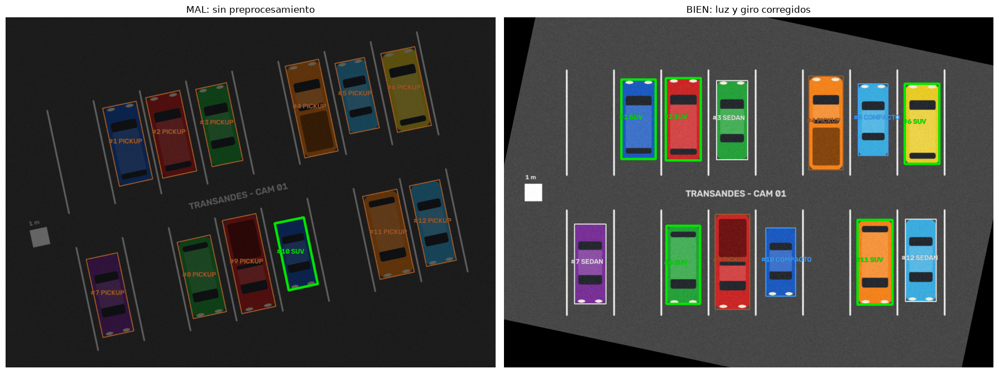

,id,cx,cy,largo_m,ancho_m,relacion,area_m2,tono_h,color,tipo,es_suv,motivo
0,1,385,291,4.56,1.98,2.30,8.48,108.8,azul,SUV,True,ancho ≥ 1.83 m
1,2,513,290,4.72,2.02,2.34,8.96,179.9,rojo,SUV,True,ancho ≥ 1.83 m
2,3,652,293,4.54,1.80,2.52,7.69,65.2,verde,SEDAN,False,medidas intermedias
3,4,921,301,5.38,1.98,2.72,10.14,14.1,naranja,PICKUP,False,largo ≥ 5.05 m
4,5,1055,292,4.12,1.72,2.40,6.70,99.4,celeste,COMPACTO,False,largo < 4.25 m
5,6,1196,304,4.60,2.00,2.30,8.70,25.2,amarillo,SUV,True,ancho ≥ 1.83 m
6,7,247,704,4.58,1.82,2.52,7.81,140.9,morado,SEDAN,False,medidas intermedias
7,8,513,707,4.48,1.94,2.31,8.19,65.2,verde,SUV,True,ancho ≥ 1.83 m
8,9,653,698,5.46,2.00,2.73,10.34,179.9,rojo,PICKUP,False,largo ≥ 5.05 m
9,10,791,698,3.92,1.72,2.28,6.26,108.8,azul,COMPACTO,False,largo < 4.25 m


In [27]:
tabla_sin, anot_sin = inspeccionar(noche, "noche SIN corregir")
tabla_con, anot_con = inspeccionar(noche_corregida, "noche corregida")

mostrar_varias([anot_sin, anot_con], ["MAL: sin preprocesamiento", "BIEN: luz y giro corregidos"],
               columnas=2, tamano=(18, 7))
tabla_con

In [28]:
_ = decidir_contrato(tabla_sin, "Noche SIN corregir (¡decisión equivocada!)")
print()
_ = decidir_contrato(tabla_con, "Noche corregida")

tabla_con.to_csv("resultados/reporte_turno_noche.csv", index=False, encoding="utf-8-sig")
cv2.imwrite("resultados/turno_noche_inspeccionado.png", anot_con)
print("\nReporte del turno noche guardado.")

--- Noche SIN corregir (¡decisión equivocada!) ---
tipo
PICKUP    11
SUV        1 

SUV detectadas: #10 (azul)
❌ NO alcanza para el contrato. Faltan: {'SUV': 4}

--- Noche corregida ---
tipo
SUV         5
SEDAN       3
PICKUP      2
COMPACTO    2 

SUV detectadas: #1 (azul), #2 (rojo), #6 (amarillo), #8 (verde), #11 (naranja)
✅ La flota CUMPLE el contrato minero.

Reporte del turno noche guardado.


### ❓ Pregunta 4
Sin corregir, ¿por qué el sistema **no encontró el patrón** y por qué casi **todos los vehículos salieron como SUV o PICKUP**? Relaciona tu respuesta con el canal **V**, el umbral `V > 200` del patrón y la escala por defecto de 40 px/m. ¿Por qué el **giro** de la cámara casi no afecta las medidas? (pista: `minAreaRect`).

*Escribe tu respuesta aquí:*

---
## Paso 10 · De las reglas al **Machine Learning**

Hasta ahora **nosotros** escribimos las reglas. En *Machine Learning* el modelo **aprende** a partir de ejemplos etiquetados.

`datos/flota_etiquetada.csv` tiene 320 vehículos medidos por el área de mantenimiento, con un **6 % de etiquetas erróneas** (errores humanos). Entrenaremos dos modelos:
- **k-NN**: busca los *k* vehículos más parecidos y vota.
- **Árbol de decisión**: aprende reglas `if / else` como las nuestras, ¡y podemos leerlas!

(320, 4)


,largo_m,ancho_m,relacion,tipo
0,4.67,1.95,2.388,SUV
1,4.70,1.93,2.434,SUV
2,4.05,1.60,2.534,COMPACTO
3,4.04,1.63,2.481,COMPACTO
4,4.54,1.99,2.282,SUV


tipo
SUV         96
COMPACTO    86
SEDAN       85
PICKUP      53
Name: count, dtype: int64


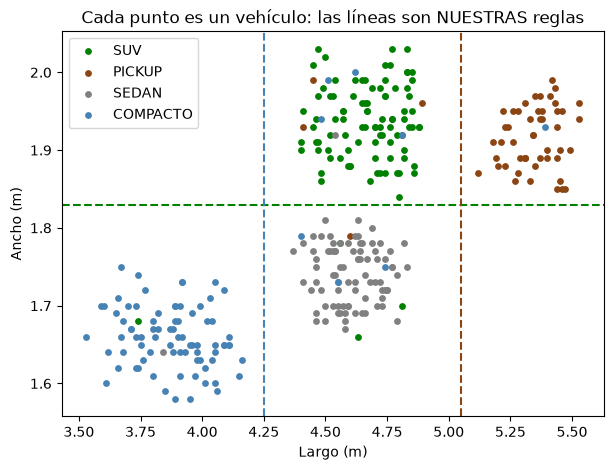

In [29]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

datos = pd.read_csv("datos/flota_etiquetada.csv")
print(datos.shape)
display(datos.head())
print(datos["tipo"].value_counts())

plt.figure(figsize=(7, 5))
for tipo, col in zip(orden, ["green", "saddlebrown", "gray", "steelblue"]):
    d = datos[datos["tipo"] == tipo]
    plt.scatter(d["largo_m"], d["ancho_m"], s=15, c=col, label=tipo)
plt.axhline(NORMA["ancho_suv_m"], ls="--", c="green")
plt.axvline(NORMA["largo_pickup_m"], ls="--", c="saddlebrown")
plt.axvline(NORMA["largo_compacto_m"], ls="--", c="steelblue")
plt.xlabel("Largo (m)"); plt.ylabel("Ancho (m)")
plt.title("Cada punto es un vehículo: las líneas son NUESTRAS reglas")
plt.legend()
plt.show()

Exactitud k-NN : 95.0%
Exactitud Árbol: 95.0%


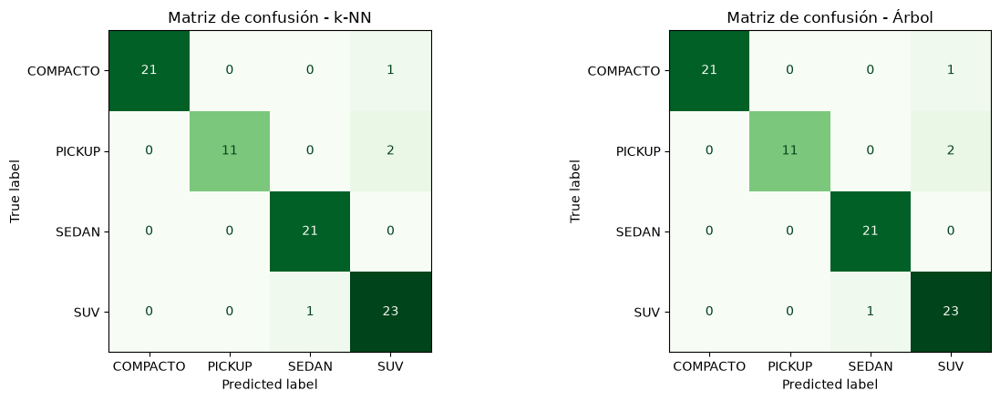

In [30]:
X = datos[["largo_m", "ancho_m", "relacion"]]     # matriz de características
y = datos["tipo"]                                  # vector de etiquetas
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=1, stratify=y)

knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7))    # 🧪 prueba k = 1, 3, 15
knn.fit(X_train, y_train)
arbol = DecisionTreeClassifier(max_depth=3, random_state=0)                   # 🧪 prueba max_depth = 1, 2, 10
arbol.fit(X_train, y_train)

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
for eje, (nombre, modelo) in zip(ejes, [("k-NN", knn), ("Árbol", arbol)]):
    pred = modelo.predict(X_test)
    print(f"Exactitud {nombre:5s}: {accuracy_score(y_test, pred):.1%}")
    ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=eje, cmap="Greens", colorbar=False)
    eje.set_title(f"Matriz de confusión - {nombre}")
plt.tight_layout()
plt.show()

|--- ancho_m <= 1.83
|   |--- largo_m <= 4.26
|   |   |--- largo_m <= 3.84
|   |   |   |--- class: COMPACTO
|   |   |--- largo_m >  3.84
|   |   |   |--- class: COMPACTO
|   |--- largo_m >  4.26
|   |   |--- relacion <= 2.47
|   |   |   |--- class: COMPACTO
|   |   |--- relacion >  2.47
|   |   |   |--- class: SEDAN
|--- ancho_m >  1.83
|   |--- largo_m <= 4.88
|   |   |--- relacion <= 2.31
|   |   |   |--- class: SUV
|   |   |--- relacion >  2.31
|   |   |   |--- class: SUV
|   |--- largo_m >  4.88
|   |   |--- largo_m <= 5.38
|   |   |   |--- class: PICKUP
|   |   |--- largo_m >  5.38
|   |   |   |--- class: PICKUP



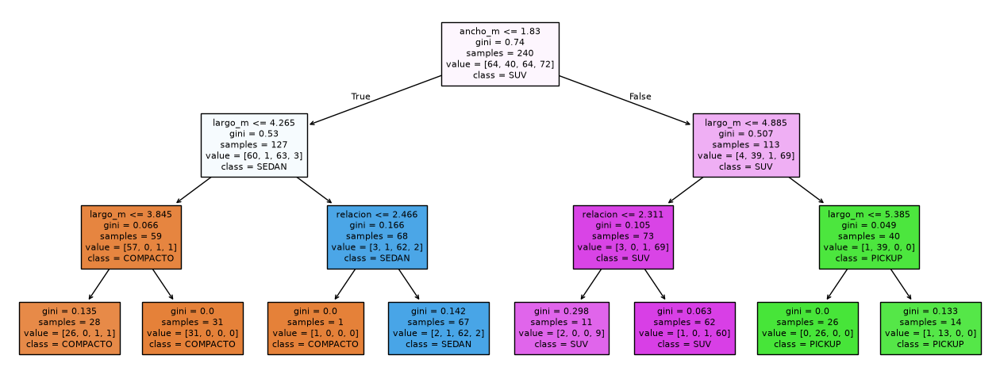

In [31]:
# Las reglas que APRENDIÓ el árbol (compáralas con NORMA)
print(export_text(arbol, feature_names=list(X.columns), decimals=2))
plt.figure(figsize=(16, 6))
plot_tree(arbol, feature_names=list(X.columns), class_names=arbol.classes_, filled=True, fontsize=8)
plt.show()

In [32]:
# ¿Los modelos opinan lo mismo que nuestras reglas en las dos fotos?
flota_total = pd.concat([reporte.assign(turno="día"), tabla_con.assign(turno="noche")], ignore_index=True)
flota_total["tipo_knn"] = knn.predict(flota_total[["largo_m", "ancho_m", "relacion"]])
flota_total["tipo_arbol"] = arbol.predict(flota_total[["largo_m", "ancho_m", "relacion"]])
print(f"Coincidencia reglas vs k-NN  : {(flota_total['tipo'] == flota_total['tipo_knn']).mean():.0%}")
print(f"Coincidencia reglas vs árbol : {(flota_total['tipo'] == flota_total['tipo_arbol']).mean():.0%}")
flota_total[["turno", "id", "largo_m", "ancho_m", "relacion", "color", "tipo", "tipo_knn", "tipo_arbol"]]

Coincidencia reglas vs k-NN  : 100%
Coincidencia reglas vs árbol : 100%


,turno,id,largo_m,ancho_m,relacion,color,tipo,tipo_knn,tipo_arbol
0,día,1,4.64,2.02,2.30,rojo,SUV,SUV,SUV
1,día,2,4.54,1.74,2.61,azul,SEDAN,SEDAN,SEDAN
2,día,3,3.90,1.62,2.41,amarillo,COMPACTO,COMPACTO,COMPACTO
3,día,4,5.32,1.96,2.71,verde,PICKUP,PICKUP,PICKUP
4,día,5,4.48,1.96,2.29,celeste,SUV,SUV,SUV
5,día,6,4.72,1.74,2.71,naranja,SEDAN,SEDAN,SEDAN
6,día,7,4.10,1.72,2.38,morado,COMPACTO,COMPACTO,COMPACTO
7,día,8,5.26,1.98,2.66,azul,PICKUP,PICKUP,PICKUP
8,día,9,4.70,2.00,2.35,verde,SUV,SUV,SUV
9,día,10,4.44,1.76,2.52,rojo,SEDAN,SEDAN,SEDAN


> **Hacia el Deep Learning:** aquí *nosotros* elegimos las características (largo, ancho, relación). Una red neuronal convolucional (**CNN**, por ejemplo con TensorFlow/Keras o detectores como YOLO) aprende sola qué mirar en los píxeles y funciona incluso con autos blancos, negros o que se tocan entre sí.

---
## Paso 11 · Validación: ¿qué tan confiable es el detector de SUV?

Un buen ingeniero no confía en **una** foto. Generamos **20 patios aleatorios** (tipos, colores y plazas al azar), los inspeccionamos y comparamos con la verdad del simulador.

- **Precisión SUV**: de todo lo que el sistema llamó SUV, ¿cuánto era SUV de verdad?
- **Sensibilidad (recall) SUV**: de todas las SUV reales, ¿cuántas encontró?

[patio 100] escala=50.0 px/m | vehículos=13 | {'COMPACTO': 5, 'SEDAN': 3, 'PICKUP': 3, 'SUV': 2}
[patio 101] escala=50.0 px/m | vehículos=10 | {'SEDAN': 4, 'PICKUP': 3, 'SUV': 2, 'COMPACTO': 1}


[patio 102] escala=50.0 px/m | vehículos=11 | {'SUV': 4, 'PICKUP': 3, 'SEDAN': 3, 'COMPACTO': 1}


[patio 103] escala=50.0 px/m | vehículos=11 | {'PICKUP': 4, 'COMPACTO': 3, 'SUV': 2, 'SEDAN': 2}


[patio 104] escala=50.0 px/m | vehículos=12 | {'PICKUP': 5, 'SEDAN': 3, 'SUV': 2, 'COMPACTO': 2}


[patio 105] escala=50.0 px/m | vehículos=9 | {'COMPACTO': 4, 'PICKUP': 3, 'SEDAN': 2}
[patio 106] escala=50.0 px/m | vehículos=11 | {'COMPACTO': 5, 'SEDAN': 3, 'SUV': 2, 'PICKUP': 1}


[patio 107] escala=50.0 px/m | vehículos=8 | {'SEDAN': 3, 'SUV': 2, 'PICKUP': 2, 'COMPACTO': 1}
[patio 108] escala=50.0 px/m | vehículos=8 | {'SEDAN': 4, 'SUV': 2, 'COMPACTO': 1, 'PICKUP': 1}


... (3 outputs left out)

[patio 114] escala=50.0 px/m | vehículos=9 | {'COMPACTO': 3, 'SUV': 3, 'SEDAN': 2, 'PICKUP': 1}


[patio 115] escala=50.0 px/m | vehículos=12 | {'SEDAN': 4, 'COMPACTO': 4, 'SUV': 2, 'PICKUP': 2}
[patio 116] escala=50.0 px/m | vehículos=9 | {'SUV': 4, 'PICKUP': 3, 'SEDAN': 1, 'COMPACTO': 1}


[patio 117] escala=50.0 px/m | vehículos=8 | {'COMPACTO': 3, 'PICKUP': 2, 'SEDAN': 2, 'SUV': 1}
[patio 118] escala=50.0 px/m | vehículos=10 | {'SUV': 4, 'PICKUP': 3, 'COMPACTO': 3}


[patio 119] escala=50.0 px/m | vehículos=10 | {'SEDAN': 4, 'SUV': 3, 'COMPACTO': 3}

Vehículos evaluados: 204 | exactitud de tipo: 100.0%
Aciertos de color: 100.0%
              precision    recall  f1-score   support

    COMPACTO       1.00      1.00      1.00        54
      PICKUP       1.00      1.00      1.00        53
       SEDAN       1.00      1.00      1.00        52
         SUV       1.00      1.00      1.00        45

    accuracy                           1.00       204
   macro avg       1.00      1.00      1.00       204
weighted avg       1.00      1.00      1.00       204



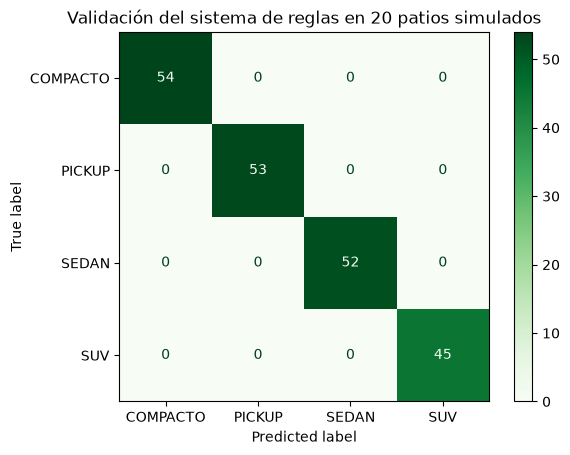

In [33]:
from sklearn.metrics import classification_report

def flota_aleatoria(semilla):
    rng = np.random.default_rng(semilla)
    plazas = [(f, c) for f in range(2) for c in range(8)]
    elegidas = rng.choice(len(plazas), rng.integers(8, 15), replace=False)
    return [{"plaza": plazas[i], "tipo": rng.choice(list(CATALOGO)), "pintura": rng.choice(list(PINTURAS))}
            for i in elegidas]

N_PATIOS = 20                                     # 🧪 prueba con 50
resultados = []
for s in range(100, 100 + N_PATIOS):
    foto, verdad = generar_patio(flota_aleatoria(s), semilla=s)
    tabla, _ = inspeccionar(foto, f"patio {s}")
    comp = comparar_con_verdad(tabla, verdad)
    comp["patio"] = s
    comp["no_detectados"] = len(verdad) - len(tabla)
    resultados.append(comp)

validacion = pd.concat(resultados, ignore_index=True)
print(f"\nVehículos evaluados: {len(validacion)} | exactitud de tipo: {validacion['acierto'].mean():.1%}")
print(f"Aciertos de color: {(validacion['color_sistema'] == validacion['color_real']).mean():.1%}")
print(classification_report(validacion["tipo_real"], validacion["tipo_sistema"], zero_division=0))
ConfusionMatrixDisplay.from_predictions(validacion["tipo_real"], validacion["tipo_sistema"], cmap="Greens")
plt.title("Validación del sistema de reglas en 20 patios simulados")
plt.show()

---
## ✅ Cierre y entregable

### Lo que construiste
Un prototipo que, con una sola foto cenital del patio, **detecta** cada vehículo con una caja rotada, **mide** su largo y ancho en metros, reconoce su **color**, lo **clasifica** (COMPACTO, SEDÁN, **SUV**, PICKUP), indica **cuáles son SUV** y decide si la flota **cumple el contrato**. Además corregiste automáticamente una cámara girada y sin luz, comparaste reglas con dos modelos de ML y **validaste** el sistema en 20 escenarios.

### ❓ Pregunta 5 (reflexión final)
Menciona **dos limitaciones** del prototipo en un patio real (vehículos blancos/negros/plateados, autos pegados entre sí, sombras, lluvia, cámara no cenital) y propón **una mejora** para cada una.

*Escribe tu respuesta aquí:*

### Entregable
- [ ] Este notebook **ejecutado completo** con las 5 preguntas respondidas.
- [ ] `resultados/turno_dia_inspeccionado.png` y `resultados/turno_noche_inspeccionado.png`.
- [ ] `resultados/reporte_turno_dia.csv` y `resultados/reporte_turno_noche.csv`.
- [ ] Captura de un experimento propio (🧪 Pruébalo tú) explicando qué cambió.

### Reto extra (opcional)
1. Agrega a `PINTURAS` un vehículo **blanco** `(235, 235, 235)` en `FLOTA_DIA` y observa qué pasa. Propón una segmentación que lo detecte (pista: diferencia con una foto del patio vacío).
2. Agrega la regla: una SUV con `relacion > 2.6` se marca como "SUV dudosa" para revisión manual.